In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('../data/final_metropole/Merge_final_2.csv', dtype={"code_dept": str})
df["date"] = pd.to_datetime(df["date_semaine"] + "-1", format="%G-S%V-%u")

CIBLE = "0an_bronchiolite_urgences"
EXOS  = ["temperature_kelvin", "humidite_relative", "O3"]

# --- Une ligne par département et par semaine t : cible y(t+1), variables connues en t ---
morceaux = []
for dept, d in df.groupby("code_dept"):
    d = d.drop_duplicates("date").set_index("date").sort_index().asfreq("W-MON")   # grille hebdo régulière
    y, sem = d[CIBLE], d.index.isocalendar().week.astype(float)
    morceaux.append(pd.DataFrame({
        "code_dept": dept,
        "date_cible": d.index + pd.Timedelta(weeks=1),
        "cible": y.shift(-1),                                    # y(t+1)
        "y_lag0": y, "y_lag1": y.shift(1), "y_lag2": y.shift(2),
        "sem_sin": np.sin(2 * np.pi * sem / 52.18),
        "sem_cos": np.cos(2 * np.pi * sem / 52.18),
        **{c: d[c] for c in EXOS},
    }))
panel = pd.concat(morceaux).dropna(subset=["cible", "y_lag0", "y_lag1", "y_lag2"])

# --- Découpage sur l'année de la cible ---
an = panel["date_cible"].dt.year
panel["split"] = np.select([an <= 2022, an == 2023], ["train", "val"], default="test")

#FEATURES = ["y_lag0", "y_lag1", "y_lag2", "sem_sin", "sem_cos"] + EXOS
FEATURES = ["y_lag1", "y_lag2", "sem_sin", "sem_cos"] + EXOS
print(panel["split"].value_counts())

split
train    9598
val      4980
test     4955
Name: count, dtype: int64


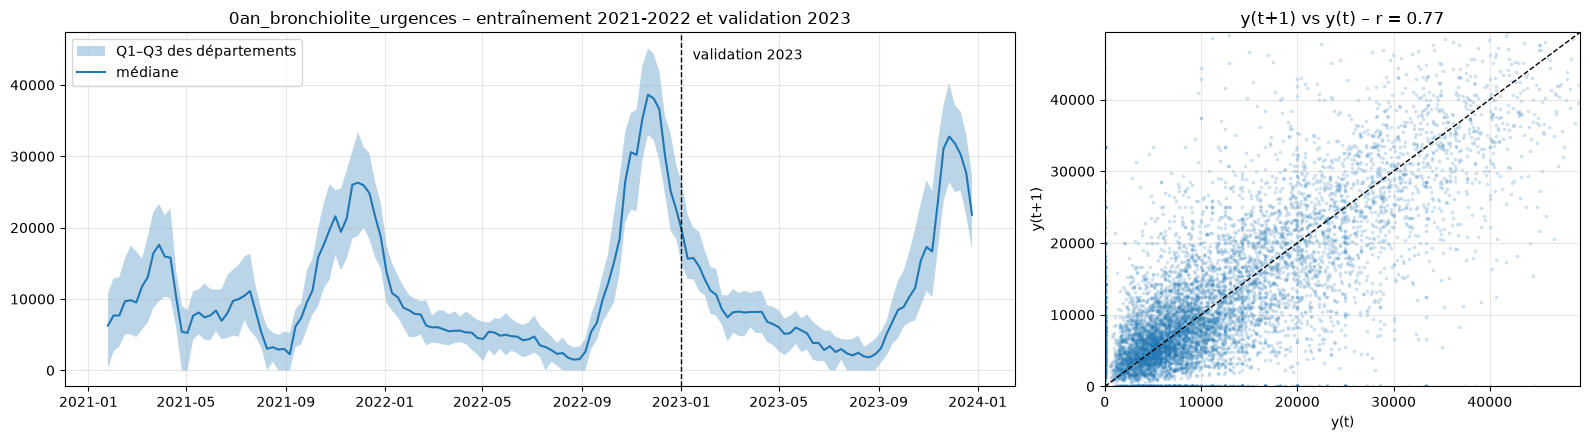

In [28]:
pv = panel[panel["split"] != "test"]                 # 2024 exclu
tr = pv[pv["split"] == "train"]

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5), gridspec_kw={"width_ratios": [2, 1]})

# 1. Série nationale : médiane et intervalle interquartile entre départements
g = pv.groupby("date_cible")["cible"]
med, q1, q3 = g.median(), g.quantile(.25), g.quantile(.75)
ax = axes[0]
ax.fill_between(med.index, q1, q3, alpha=.3, label="Q1–Q3 des départements")
ax.plot(med, lw=1.5, label="médiane")
ax.axvline(pd.Timestamp("2023-01-01"), color="k", ls="--", lw=1)
ax.text(pd.Timestamp("2023-01-15"), ax.get_ylim()[1] * .92, "validation 2023")
ax.set_title(f"{CIBLE} – entraînement 2021-2022 et validation 2023")
ax.legend(loc="upper left")
ax.grid(alpha=.3)

# 2. Cible y(t+1) contre y(t), sur l'entraînement
ax = axes[1]
s = tr[["y_lag0", "cible"]].dropna()
ax.scatter(s["y_lag0"], s["cible"], s=3, alpha=.15)
lim = [0, np.nanpercentile(s.values, 99.5)]
ax.plot(lim, lim, "k--", lw=1)                        # diagonale y = x
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("y(t)"); ax.set_ylabel("y(t+1)")
ax.set_title(f"y(t+1) vs y(t) – r = {s.corr().iloc[0, 1]:.2f}")
ax.grid(alpha=.3)

plt.tight_layout()
plt.show()


In [29]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score, classification_report
from xgboost import XGBClassifier

SEUIL = 1.5                                            # hausse si y(t+1) > SEUIL * y(t)

# --- Cible binaire et baseline ---
panel["hausse"]      = (panel["cible"]  > SEUIL * panel["y_lag0"]).astype(int)
panel["hausse_prec"] = (panel["y_lag0"] > SEUIL * panel["y_lag1"]).astype(int)   # baseline : même évolution que t

tr = panel[panel["split"] == "train"]
va = panel[panel["split"] == "val"]
print("Proportion de hausses :", tr["hausse"].mean().round(3), "(train) /",
      va["hausse"].mean().round(3), "(val)")
print("Lignes avec y(t) = 0 :", int((panel["y_lag0"] == 0).sum()))

X_tr, y_tr = tr[FEATURES], tr["hausse"]
X_va, y_va = va[FEATURES], va["hausse"]

# --- Modèles ---
modeles = {
    "Régression logistique": make_pipeline(StandardScaler(),
                                           LogisticRegression(class_weight="balanced", max_iter=1000)),
    "XGBoost": XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05,
                             scale_pos_weight=(y_tr == 0).sum() / (y_tr == 1).sum(),
                             eval_metric="logloss", random_state=0),
}

# --- Évaluation sur 2023 ---
print("\n=== Baseline : même évolution que la semaine précédente ===")
print("AUC ROC :", round(roc_auc_score(y_va, va["hausse_prec"]), 3))
print(classification_report(y_va, va["hausse_prec"], target_names=["pas de hausse", "hausse"], digits=3))

for nom, mod in modeles.items():
    mod.fit(X_tr, y_tr)
    proba = mod.predict_proba(X_va)[:, 1]
    print(f"\n=== {nom} ===")
    print("AUC ROC :", round(roc_auc_score(y_va, proba), 3))
    print(classification_report(y_va, (proba >= 0.5).astype(int),
                                target_names=["pas de hausse", "hausse"], digits=3))

Proportion de hausses : 0.231 (train) / 0.227 (val)
Lignes avec y(t) = 0 : 2798

=== Baseline : même évolution que la semaine précédente ===
AUC ROC : 0.424
               precision    recall  f1-score   support

pas de hausse      0.738     0.737     0.738      3849
       hausse      0.111     0.111     0.111      1131

     accuracy                          0.595      4980
    macro avg      0.425     0.424     0.424      4980
 weighted avg      0.596     0.595     0.595      4980


=== Régression logistique ===
AUC ROC : 0.62
               precision    recall  f1-score   support

pas de hausse      0.845     0.472     0.605      3849
       hausse      0.282     0.705     0.402      1131

     accuracy                          0.525      4980
    macro avg      0.563     0.588     0.504      4980
 weighted avg      0.717     0.525     0.559      4980


=== XGBoost ===
AUC ROC : 0.639
               precision    recall  f1-score   support

pas de hausse      0.835     0.576     0.6

Départements : part de semaines à 0 ou NA (2021-2022)
count    96.000
mean      0.156
std       0.199
min       0.000
25%       0.010
50%       0.048
75%       0.231
max       0.760
Name: part_0_NA, dtype: float64


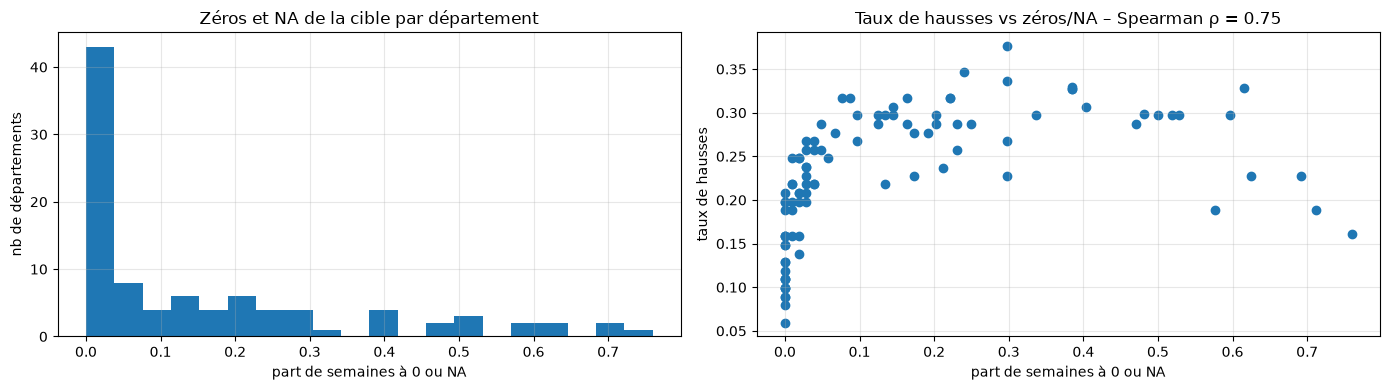

,Q_MIN,Y_MIN,lignes_gardees,taux_hausse,n_dept,rho_0NA_hausse,IQR_dept
0,0.00,0.000,1.000,0.231,96,0.746,0.109
1,0.05,0.000,1.000,0.231,96,0.746,0.109
2,0.10,0.000,1.000,0.231,96,0.746,0.109
3,0.15,1139.205,0.850,0.187,96,0.435,0.071
4,0.20,2702.703,0.800,0.162,96,0.596,0.067
5,0.25,3703.704,0.751,0.143,96,0.585,0.067
6,0.30,4545.455,0.702,0.130,96,0.623,0.063
7,0.35,5325.331,0.650,0.121,96,0.671,0.073
8,0.40,6250.000,0.603,0.111,96,0.698,0.060
9,0.45,7142.857,0.554,0.101,95,0.661,0.064


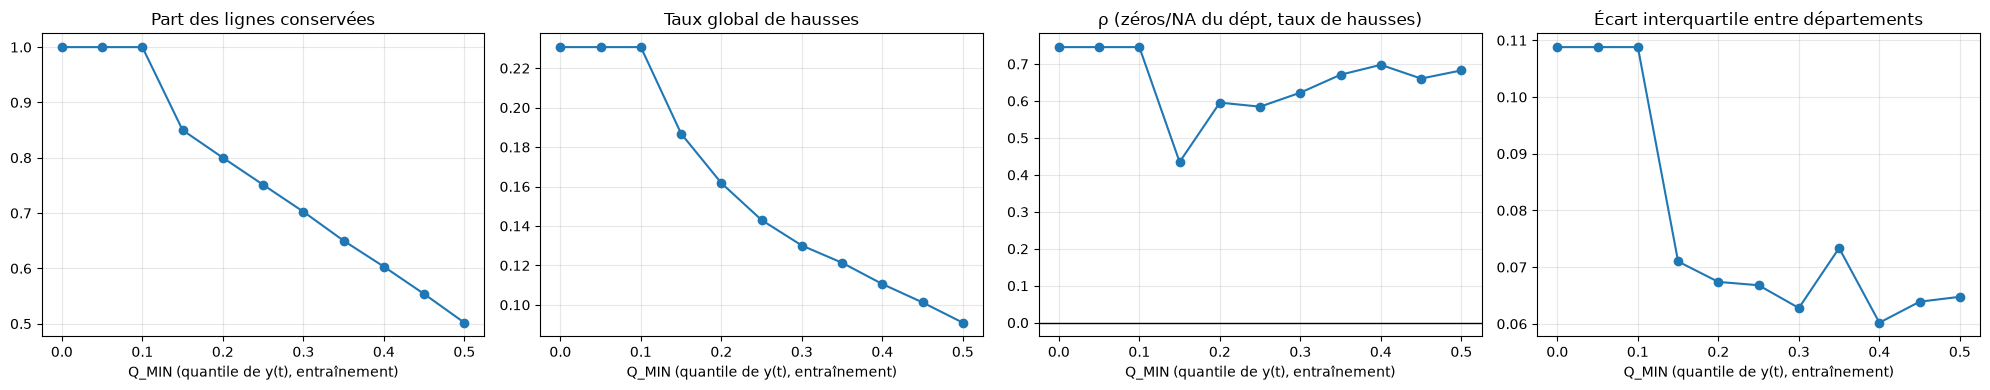

In [30]:
# --- Données d'entraînement uniquement, panel non modifié ---
tr_all = panel[panel["split"] == "train"].copy()
tr_all["hausse"] = (tr_all["cible"] > SEUIL * tr_all["y_lag0"]).astype(int)

# ===== 1. Zéros et NA de la cible par département (2021-2022, à partir de df) =====
d_tr = df[df["date"].dt.year <= 2022]
qual = d_tr.groupby("code_dept")[CIBLE].agg(part_NA=lambda s: s.isna().mean(),
                                             part_0=lambda s: (s == 0).mean())
qual["part_0_NA"] = qual["part_NA"] + qual["part_0"]
qual["taux_hausse"] = tr_all.groupby("code_dept")["hausse"].mean()
rho0 = qual["part_0_NA"].corr(qual["taux_hausse"], method="spearman")

print("Départements : part de semaines à 0 ou NA (2021-2022)")
print(qual["part_0_NA"].describe().round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(qual["part_0_NA"], bins=20)
axes[0].set_xlabel("part de semaines à 0 ou NA"); axes[0].set_ylabel("nb de départements")
axes[0].set_title("Zéros et NA de la cible par département")
axes[1].scatter(qual["part_0_NA"], qual["taux_hausse"])
axes[1].set_xlabel("part de semaines à 0 ou NA"); axes[1].set_ylabel("taux de hausses")
axes[1].set_title(f"Taux de hausses vs zéros/NA – Spearman ρ = {rho0:.2f}")
for ax in axes:
    ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

# ===== 2. Recherche d'un niveau minimal commun Y_MIN =====
N_MIN_DEPT = 20                                     # nb minimal de lignes pour calculer le taux d'un département
lignes = []
for q in np.round(np.arange(0, 0.55, 0.05), 2):
    y_min = tr_all["y_lag0"].quantile(q)
    k = tr_all[tr_all["y_lag0"] >= y_min]
    g = k.groupby("code_dept")["hausse"].agg(["mean", "size"])
    g = g[g["size"] >= N_MIN_DEPT]
    lignes.append({"Q_MIN": q, "Y_MIN": y_min,
                   "lignes_gardees": len(k) / len(tr_all),
                   "taux_hausse": k["hausse"].mean(),
                   "n_dept": len(g),
                   "rho_0NA_hausse": qual["part_0_NA"].corr(g["mean"], method="spearman"),
                   "IQR_dept": g["mean"].quantile(.75) - g["mean"].quantile(.25)})
seuils = pd.DataFrame(lignes)
display(seuils.round(3))

fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, col, titre in zip(axes,
                          ["lignes_gardees", "taux_hausse", "rho_0NA_hausse", "IQR_dept"],
                          ["Part des lignes conservées", "Taux global de hausses",
                           "ρ (zéros/NA du dépt, taux de hausses)", "Écart interquartile entre départements"]):
    ax.plot(seuils["Q_MIN"], seuils[col], "o-")
    ax.set_xlabel("Q_MIN (quantile de y(t), entraînement)")
    ax.set_title(titre)
    ax.grid(alpha=.3)
axes[2].axhline(0, color="k", lw=1)
plt.tight_layout(); plt.show()

In [31]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score, classification_report
from xgboost import XGBClassifier

SEUIL = 1.5                                            # hausse si y(t+1) > SEUIL * y(t)
Q_MIN = 0.15                                           # niveau minimal : quantile de y(t) sur 2021-2022

# --- Niveau minimal commun, calculé sur l'entraînement ---
Y_MIN = panel.loc[panel["split"] == "train", "y_lag0"].quantile(Q_MIN)
panel_c = panel[panel["y_lag0"] >= Y_MIN].copy()
print(f"Y_MIN = {Y_MIN:.0f} ; lignes conservées : {len(panel_c) / len(panel):.1%}")

# --- Cible binaire et baseline ---
panel_c["hausse"]      = (panel_c["cible"]  > SEUIL * panel_c["y_lag0"]).astype(int)
panel_c["hausse_prec"] = (panel_c["y_lag0"] > SEUIL * panel_c["y_lag1"]).astype(int)   # même évolution que t

tr = panel_c[panel_c["split"] == "train"]
va = panel_c[panel_c["split"] == "val"]
print("Proportion de hausses :", tr["hausse"].mean().round(3), "(train) /",
      va["hausse"].mean().round(3), "(val)")

X_tr, y_tr = tr[FEATURES], tr["hausse"]
X_va, y_va = va[FEATURES], va["hausse"]

# --- Modèles ---
modeles = {
    "Régression logistique": make_pipeline(StandardScaler(),
                                           LogisticRegression(class_weight="balanced", max_iter=1000)),
    "XGBoost": XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05,
                             scale_pos_weight=(y_tr == 0).sum() / (y_tr == 1).sum(),
                             eval_metric="logloss", random_state=0),
}

# --- Évaluation sur 2023 ---
print("\n=== Baseline : même évolution que la semaine précédente ===")
print("AUC ROC :", round(roc_auc_score(y_va, va["hausse_prec"]), 3))
print(classification_report(y_va, va["hausse_prec"], target_names=["pas de hausse", "hausse"], digits=3))

for nom, mod in modeles.items():
    mod.fit(X_tr, y_tr)
    proba = mod.predict_proba(X_va)[:, 1]
    print(f"\n=== {nom} ===")
    print("AUC ROC :", round(roc_auc_score(y_va, proba), 3))
    print(classification_report(y_va, (proba >= 0.5).astype(int),
                                target_names=["pas de hausse", "hausse"], digits=3))


Y_MIN = 1139 ; lignes conservées : 85.0%
Proportion de hausses : 0.187 (train) / 0.185 (val)

=== Baseline : même évolution que la semaine précédente ===
AUC ROC : 0.434
               precision    recall  f1-score   support

pas de hausse      0.788     0.709     0.746      3474
       hausse      0.110     0.159     0.130       788

     accuracy                          0.607      4262
    macro avg      0.449     0.434     0.438      4262
 weighted avg      0.663     0.607     0.632      4262


=== Régression logistique ===
AUC ROC : 0.624
               precision    recall  f1-score   support

pas de hausse      0.879     0.487     0.627      3474
       hausse      0.238     0.706     0.356       788

     accuracy                          0.527      4262
    macro avg      0.559     0.596     0.491      4262
 weighted avg      0.761     0.527     0.577      4262


=== XGBoost ===
AUC ROC : 0.645
               precision    recall  f1-score   support

pas de hausse      0.870    

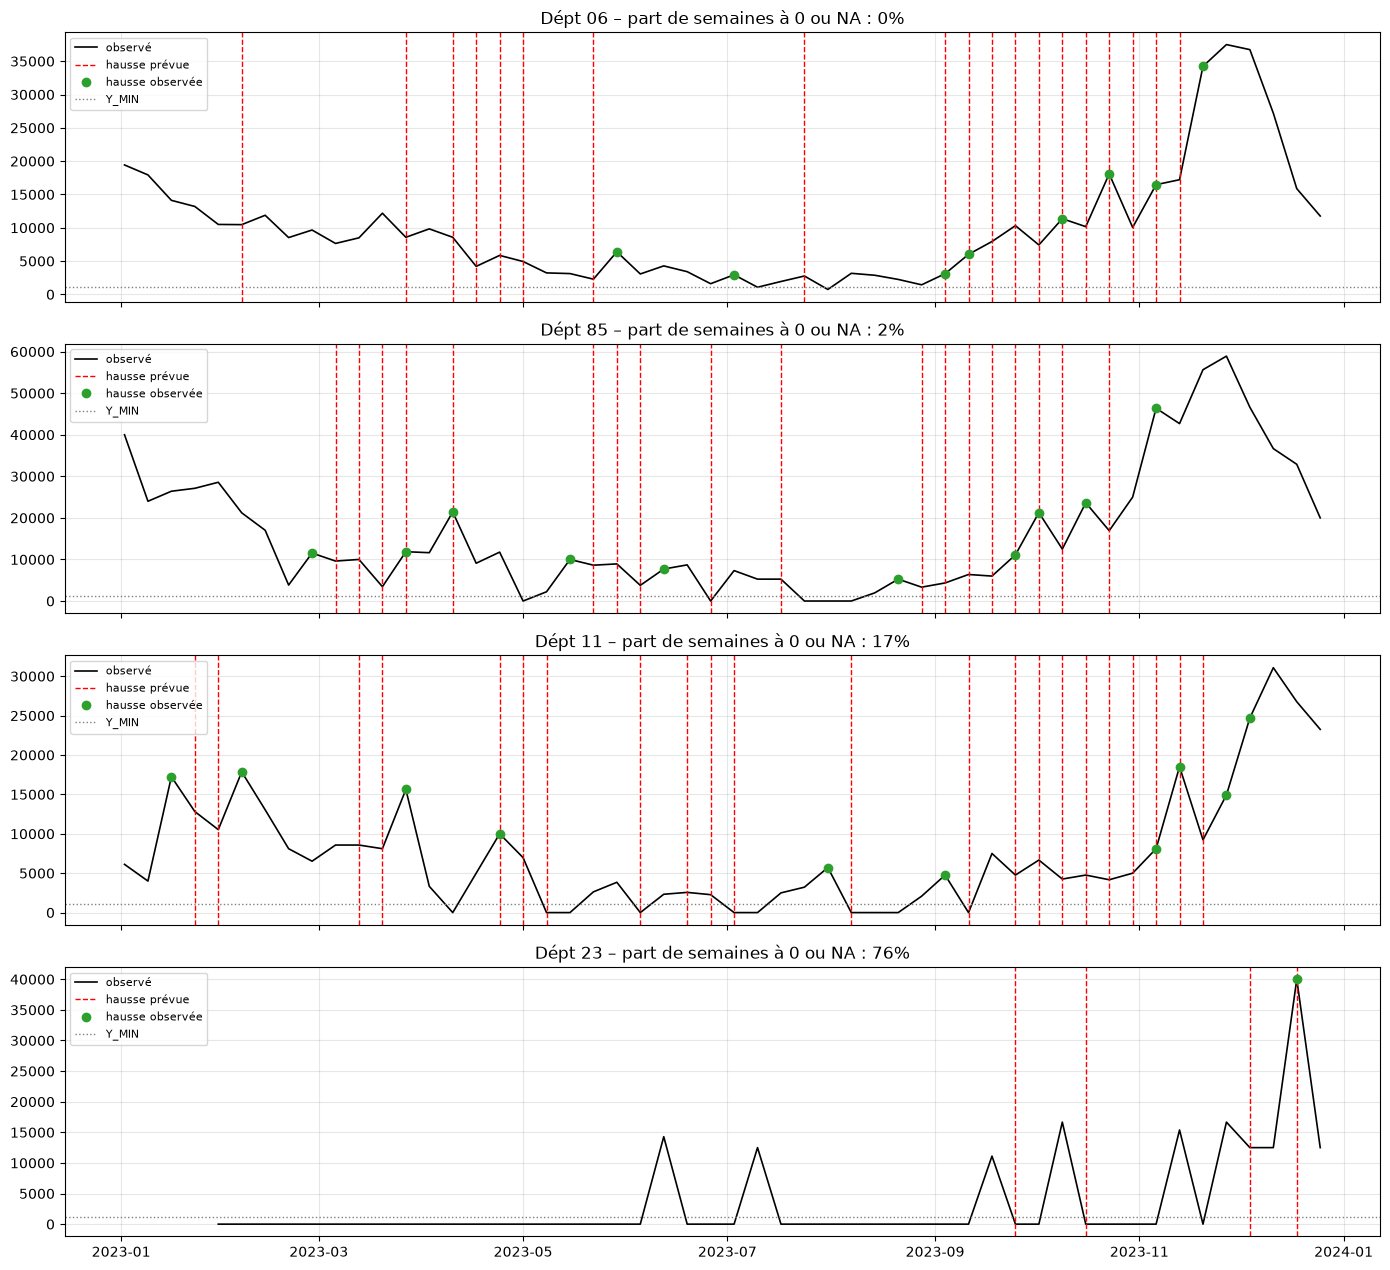

In [32]:
# --- Prévisions XGBoost sur 2023 ---
xgb = modeles["XGBoost"]
va = va.copy()
va["proba"] = xgb.predict_proba(va[FEATURES])[:, 1]
va["prevue"] = va["proba"] >= 0.5

# --- 4 départements types : répartis selon la part de zéros/NA (du plus régulier au plus lacunaire) ---
q = qual.loc[qual.index.isin(va["code_dept"].unique()), "part_0_NA"].sort_values()
DEPTS = [q.index[int(round(i * (len(q) - 1) / 3))] for i in range(4)]

fig, axes = plt.subplots(len(DEPTS), 1, figsize=(14, 3.2 * len(DEPTS)), sharex=True)
for ax, dept in zip(axes, DEPTS):
    serie = panel[(panel["code_dept"] == dept) & (panel["split"] == "val")].set_index("date_cible")["cible"]
    v = va[va["code_dept"] == dept].set_index("date_cible")
    ax.plot(serie, "k", lw=1.2, label="observé")
    for i, dt in enumerate(v.index[v["prevue"]]):
        ax.axvline(dt, color="r", ls="--", lw=1, label="hausse prévue" if i == 0 else None)
    reel = v.index[v["hausse"] == 1]
    ax.plot(reel, serie.reindex(reel), "o", color="tab:green", label="hausse observée")
    ax.axhline(Y_MIN, color="grey", ls=":", lw=1, label="Y_MIN")
    ax.set_title(f"Dépt {dept} – part de semaines à 0 ou NA : {q[dept]:.0%}")
    ax.grid(alpha=.3)
    ax.legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

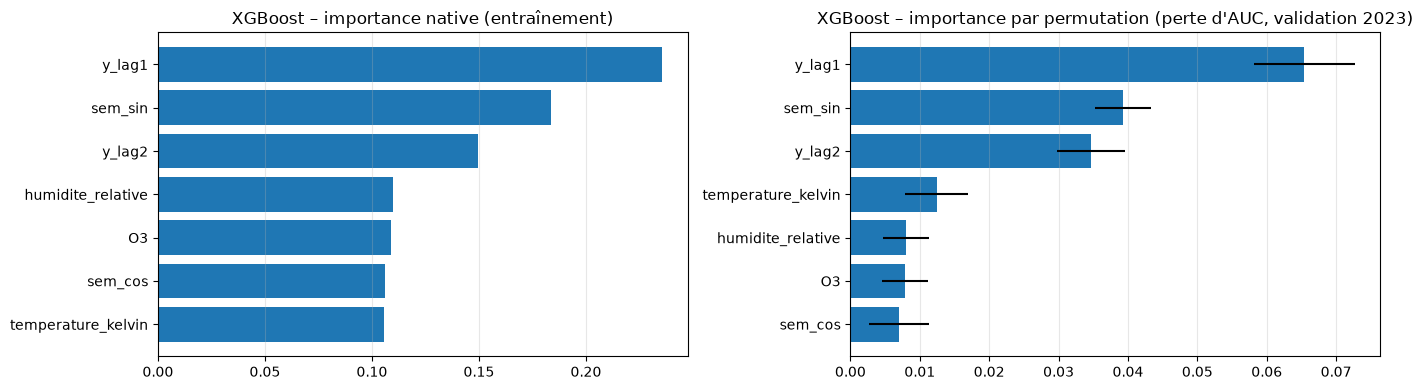

In [33]:
from sklearn.inspection import permutation_importance

xgb = modeles["XGBoost"]

# 1. Importance native (gain dans les arbres, entraînement)
imp_nat = pd.Series(xgb.feature_importances_, index=FEATURES).sort_values()

# 2. Importance par permutation sur la validation 2023 (perte d'AUC)
perm = permutation_importance(xgb, X_va, y_va, scoring="roc_auc", n_repeats=10, random_state=0)
imp_perm = pd.Series(perm.importances_mean, index=FEATURES).sort_values()
err_perm = pd.Series(perm.importances_std, index=FEATURES).reindex(imp_perm.index)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].barh(imp_nat.index, imp_nat.values)
axes[0].set_title("XGBoost – importance native (entraînement)")
axes[1].barh(imp_perm.index, imp_perm.values, xerr=err_perm.values)
axes[1].set_title("XGBoost – importance par permutation (perte d'AUC, validation 2023)")
for ax in axes:
    ax.grid(axis="x", alpha=.3)
plt.tight_layout()
plt.show()

In [34]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score, classification_report
from xgboost import XGBClassifier

SEUIL    = 1.5          # hausse si y(t+1) > SEUIL * y(t)
Q_MIN    = 0.15         # niveau minimal : quantile de y(t) sur 2021-2022
PART_MAX = 0.5          # départements exclus si la cible est sous Y_MIN plus de PART_MAX du temps
NA_BAS   = True         # les NA de la cible comptent comme « sous le seuil »

# --- Niveau minimal commun, calculé sur l'entraînement ---
Y_MIN = panel.loc[panel["split"] == "train", "y_lag0"].quantile(Q_MIN)

# --- Départements exclus : cible sous Y_MIN plus de PART_MAX du temps en 2021-2022 ---
d_tr = df[df["date"].dt.year <= 2022]
part_bas = d_tr.groupby("code_dept")[CIBLE].apply(
    lambda s: ((s < Y_MIN) | (s.isna() & NA_BAS)).mean())
gardes = part_bas.index[part_bas <= PART_MAX]
print(f"Y_MIN = {Y_MIN:.0f} ; départements exclus ({(part_bas > PART_MAX).sum()}) :",
      sorted(part_bas.index[part_bas > PART_MAX]))

panel_c = panel[(panel["y_lag0"] >= Y_MIN) & panel["code_dept"].isin(gardes)].copy()
print(f"Lignes conservées : {len(panel_c) / len(panel):.1%}")

# --- Cible binaire et baseline ---
panel_c["hausse"]      = (panel_c["cible"]  > SEUIL * panel_c["y_lag0"]).astype(int)
panel_c["hausse_prec"] = (panel_c["y_lag0"] > SEUIL * panel_c["y_lag1"]).astype(int)   # même évolution que t

tr = panel_c[panel_c["split"] == "train"]
va = panel_c[panel_c["split"] == "val"]
print("Proportion de hausses :", tr["hausse"].mean().round(3), "(train) /",
      va["hausse"].mean().round(3), "(val)")

X_tr, y_tr = tr[FEATURES], tr["hausse"]
X_va, y_va = va[FEATURES], va["hausse"]

# --- Modèles ---
modeles = {
    "Régression logistique": make_pipeline(StandardScaler(),
                                           LogisticRegression(class_weight="balanced", max_iter=1000)),
    "XGBoost": XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05,
                             scale_pos_weight=(y_tr == 0).sum() / (y_tr == 1).sum(),
                             eval_metric="logloss", random_state=0),
}

# --- Évaluation sur 2023 ---
print("\n=== Baseline : même évolution que la semaine précédente ===")
print("AUC ROC :", round(roc_auc_score(y_va, va["hausse_prec"]), 3))
print(classification_report(y_va, va["hausse_prec"], target_names=["pas de hausse", "hausse"], digits=3))

for nom, mod in modeles.items():
    mod.fit(X_tr, y_tr)
    proba = mod.predict_proba(X_va)[:, 1]
    print(f"\n=== {nom} ===")
    print("AUC ROC :", round(roc_auc_score(y_va, proba), 3))
    print(classification_report(y_va, (proba >= 0.5).astype(int),
                                target_names=["pas de hausse", "hausse"], digits=3))

Y_MIN = 1139 ; départements exclus (9) : ['09', '23', '27', '2A', '43', '48', '55', '70', '90']
Lignes conservées : 80.7%
Proportion de hausses : 0.187 (train) / 0.187 (val)

=== Baseline : même évolution que la semaine précédente ===
AUC ROC : 0.439
               precision    recall  f1-score   support

pas de hausse      0.788     0.721     0.753      3263
       hausse      0.115     0.157     0.133       750

     accuracy                          0.616      4013
    macro avg      0.452     0.439     0.443      4013
 weighted avg      0.662     0.616     0.637      4013


=== Régression logistique ===
AUC ROC : 0.634
               precision    recall  f1-score   support

pas de hausse      0.881     0.486     0.626      3263
       hausse      0.242     0.713     0.361       750

     accuracy                          0.528      4013
    macro avg      0.561     0.600     0.494      4013
 weighted avg      0.761     0.528     0.577      4013


=== XGBoost ===
AUC ROC : 0.637
   